# 현장 이미지와 영상 확인
학습이 끝난 뒤 `field/`에 현장 이미지와 `field_video.mp4`를 넣고 실행합니다. 이 노트북은 눈으로 결과를 확인하는 용도입니다. 재현율이나 mAP를 측정하려면 현장 이미지에 정답 박스 라벨이 필요합니다.

In [1]:
from pathlib import Path
from random import Random
from IPython.display import display
from PIL import Image
from ultralytics import YOLO

experiment = Path.cwd()  # 노트북 폴더에서 Jupyter를 실행합니다.
field = experiment / 'field'
best = experiment / 'run' / 'weights' / 'best.pt'
if not best.is_file():
    raise FileNotFoundError(f'학습 결과가 없습니다: {best}')
model = YOLO(str(best))

In [3]:
field.exists()

True

image.png


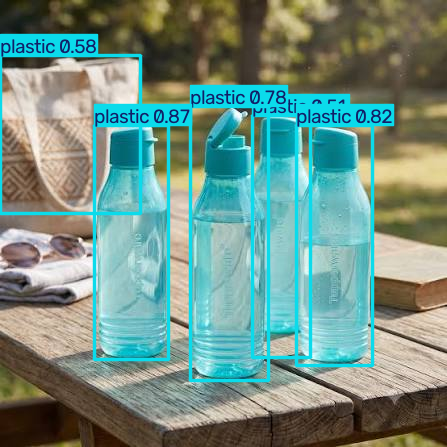

02.png


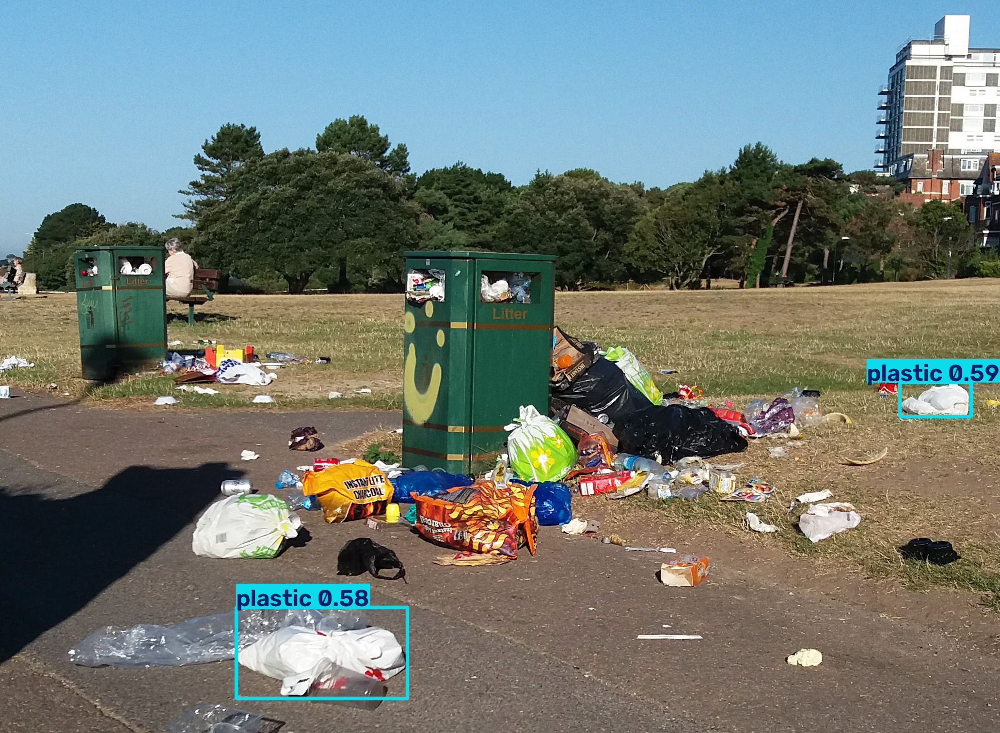

01.png


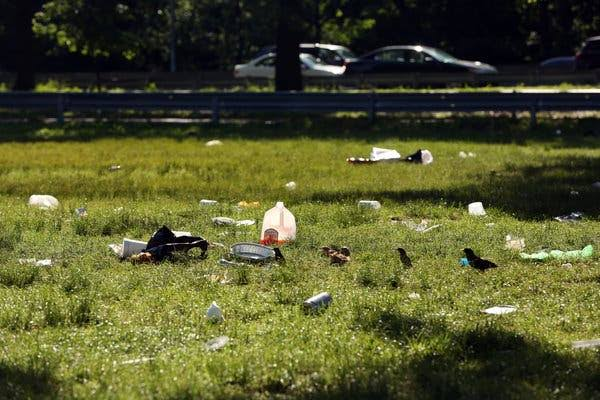

03.png


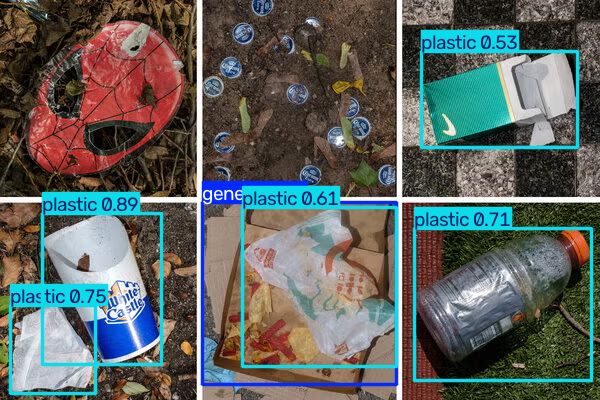

In [4]:
images = sorted(path for path in field.iterdir() if path.suffix.lower() in {'.jpg', '.jpeg', '.png'}) if field.is_dir() else []
if not images:
    raise FileNotFoundError(f'현장 이미지를 {field}에 넣어 주세요')
for image_path in Random(0).sample(images, min(5, len(images))):
    result = model.predict(source=str(image_path), conf=0.50, verbose=False)[0]
    print(image_path.name)
    display(Image.fromarray(result.plot()[..., ::-1]))

In [ ]:
video = field / 'field_video.mp4'
if video.is_file():
    for _ in model.predict(source=str(video), conf=0.10, stream=True, save=True, project=str(experiment), name='field_video'):
        pass
    print('영상 결과 폴더:', experiment / 'field_video')
else:
    print('영상 확인을 건너뜁니다:', video)

In [ ]:
import csv
from pathlib import Path
import wandb

base = Path("experiments/yolo_11n__aihub_living-v1__trash_feature_training__s0")
out = base / "run"
aliases = {
    "metrics/precision(B)": "val/precision",
    "metrics/recall(B)": "val/recall",
    "metrics/mAP50(B)": "val/map50",
    "metrics/mAP50-95(B)": "val/map50_95",
}

with wandb.init(project="jupjup", id="c8bx21zq", resume="must") as run:
    with (out / "results.csv").open(newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            values = {
                key.strip(): float(value)
                for key, value in row.items()
                if key not in {"epoch", "time"} and value
            }
            values.update({alias: values[key] for key, alias in aliases.items() if key in values})
            run.log({"epoch": int(row["epoch"]), **values})

    run.summary["train/stopped_epoch"] = 39
    artifact = wandb.Artifact("model-c8bx21zq", type="model")
    for path in (
        out / "weights/best.pt",
        out / "weights/last.pt",
        out / "results.csv",
        out / "args.yaml",
        base / "config.yaml",
    ):
        artifact.add_file(str(path))
    run.log_artifact(artifact, aliases=["best"])
    print(run.url)

image.png


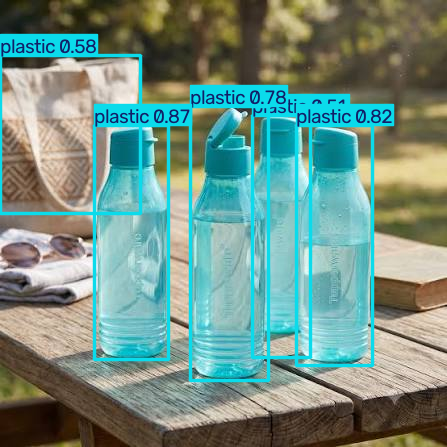

02.png


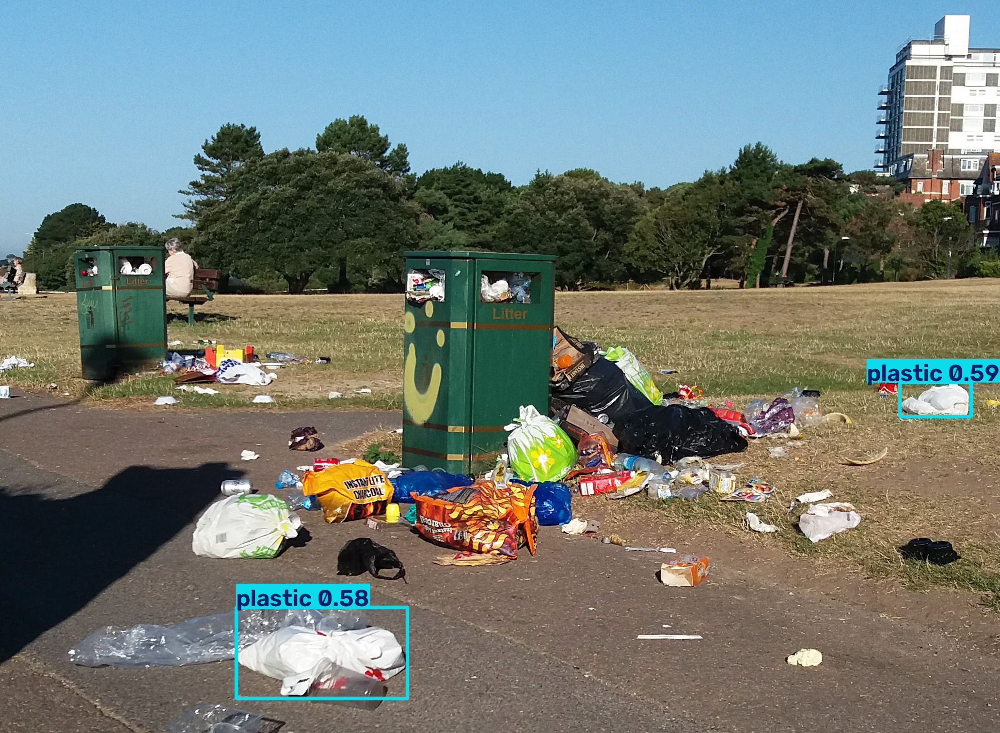

01.png


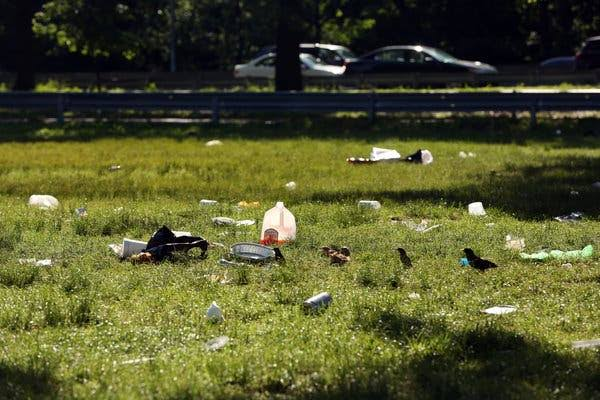

03.png


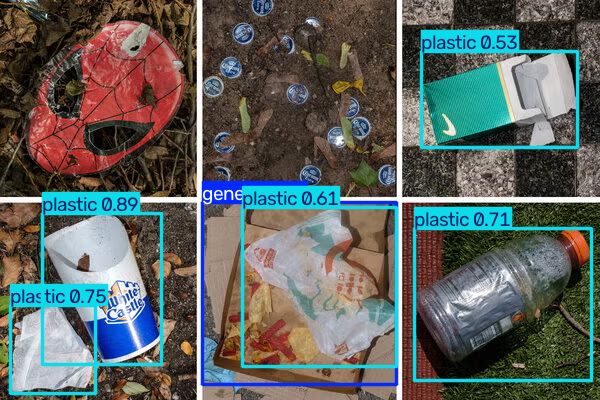

epoch,19
eval/map50,0.32248
eval/map50_95,0.24977
eval/precision,0.54373
eval/recall,0.29856
lr/pg0,0.0008
lr/pg1,0.0008
lr/pg2,0.0008
metrics/mAP50(B),0.30348
metrics/mAP50-95(B),0.22954
+18,...


In [6]:
import wandb

logged_images = []
for image_path in Random(0).sample(images, min(5, len(images))):
    result = model.predict(source=str(image_path), conf=0.50, verbose=False)[0]
    annotated = Image.fromarray(result.plot()[..., ::-1])  # BGR → RGB
    print(image_path.name)
    display(annotated)
    logged_images.append(wandb.Image(annotated, caption=image_path.name))

with wandb.init(project="jupjup", id="dajkrfu8", resume="must") as run:
    run.log({"field/predictions_conf050": logged_images})